# PANDA demo: from an MD trajectory to the contact angle

**PANDA** (`panda_md`) finds the contact angle θ and the interface shape of a liquid confined in a pore from its
one-dimensional density profile. This notebook goes through the whole analysis of a real trajectory, almost every
step being one call of the library:

| Step | Call |
|------|------|
| read the trajectory | `panda.load_trajectory` |
| measure the slit from the wall atoms | `panda.SlitPore.from_trajectory` |
| density profiles over time blocks | `panda.density_profile` |
| bulk density from the 2D map | `panda.density_map(...).bulk_density()` |
| which interface shape is it | `panda.compare_shapes` |
| θ and its error over the blocks | `panda.fit_blocks` |
| the shape seen in 2D, axis-centred | `panda.density_map(..., shape=...)` |
| which shape the capillary energy prefers | `panda.stability_diagram` |
| save, and the same from the shell | `.save`, `model_dump_json`, `panda profile / fit` |

System: a graphite slit pore with water (TIP4P) and n-decane, 10 ns (PANDA_Reborn `graphite_decane_tip4p_1.0`).
Without these files the notebook runs on a synthetic trajectory of the same structure (a water bridge in a slit).

Run with the kernel of the project environment (`uv sync --all-extras`, kernel `.venv/bin/python`).

In [1]:
import os
from pathlib import Path

import numpy as np

import panda_md as panda
from panda_md.plotting import plot_blocks, plot_density_map, plot_fit, plot_profile, plot_stability

SYSTEM = Path(os.environ.get("PANDA_REBORN_DIR", "/mnt/c/Phystech/Computing_Physics_Center/Projects/PANDA_Reborn"))
TOPOLOGY = SYSTEM / "graphite_decane_tip4p_1.0" / "graphite_decane_tip4p.tpr"
TRAJECTORY = SYSTEM / "graphite_decane_tip4p_1.0" / "graphite_decane_tip4p.xtc"
WALLS, WATER, DECANE = "resname GRAPHITE", "resname WATER and name OW", "resname DECAN*"
START, BLOCK = "2 ns", "1 ns"  # equilibration to skip, length of a time block
OUT = Path("demo_results")
OUT.mkdir(exist_ok=True)
print(f"panda-md {panda.__version__}")

panda-md 0.1.0


## 1. Trajectory and pore

The pore is measured in a frame of the trajectory: H is the empty gap between the wall atoms (across the periodic
boundary if needed), L and k come from the box. `liquid=` picks the gap that holds the liquid if the box has a
vacuum slab.

In [2]:
if TOPOLOGY.exists():
    trajectory = panda.load_trajectory(TOPOLOGY, TRAJECTORY)
else:  # no MD files: a synthetic trajectory with the same structure — a water bridge (roll) in a slit
    truth = panda.SlitPore(width_nm=8.27, length_nm=17.27, base_aspect_ratio=0.3).interface("roll")
    trajectory = panda.synthetic_trajectory(truth, {"theta": 165.0, "delta": 0.05, "phi": 0.49},
                                            density_bulk_per_nm3=33.1, frame_count=200, seed=0)
    WALLS, WATER, DECANE, START, BLOCK = "walls", "liquid", None, "0 ps", "250 ps"

pore = panda.SlitPore.from_trajectory(trajectory, walls=WALLS, liquid=WATER, time=START)
pore

slit pore: wall_selection = 'resname GRAPHITE', width_nm = 8.269, length_nm = 17.271, base_aspect_ratio = 0.296923

## 2. Density profiles over time blocks

One histogram per block of `BLOCK`; the mean over blocks is the profile to fit, the spread over blocks is its error.
The profile is centred on the pore (the middle between the walls, found in every frame) and flipped if the liquid
sits at the upper wall.

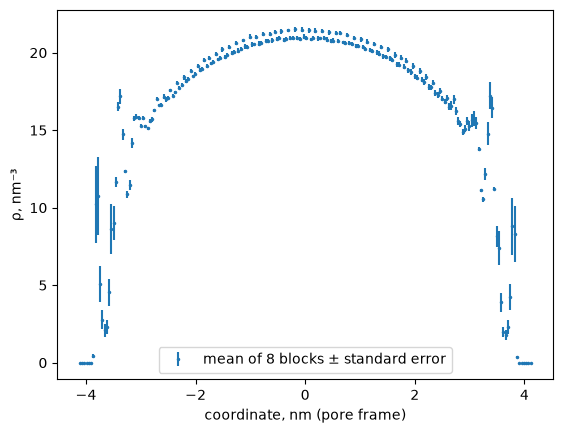

In [3]:
profiles = panda.density_profile(trajectory, pore, WATER, start=START, block=BLOCK)
plot_profile(profiles);

## 3. Bulk density from the 2D map

The fit compares ρ / ρ_bulk with the model, so it needs the bulk density of the liquid. The 2D map x–z shows the
liquid in the pore; `bulk_density()` takes the median density in the core of the phase in the middle of the slit,
away from the layering at the walls.

ρ_bulk of water ≈ 33.10 nm⁻³


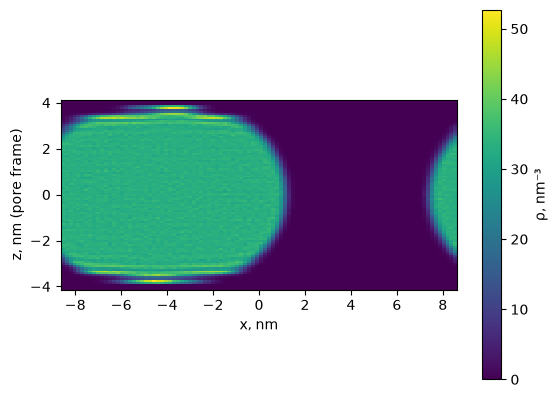

In [4]:
water_map = panda.density_map(trajectory, pore, WATER, start=START, stride=5)
rho_bulk = water_map.bulk_density()
print(f"ρ_bulk of water ≈ {rho_bulk:.2f} nm⁻³")
plot_density_map(water_map);

## 4. Which interface shape?

Every shape of the pore is fitted with the same settings and ranked by the loss. Shapes that cannot hold this volume
fraction are listed with the reason; shapes the profile cannot tell apart would be marked with «≈».

In [5]:
spec = panda.FitSpec(density_bulk_per_nm3=rho_bulk)
comparison = panda.compare_shapes(pore, profiles.mean(), spec)
print(comparison)

slit: shape comparison
  roll                     loss = 0.02617  theta = 171.1, delta = 0.0625, phi = 0.487, shift = 0
  worm                     loss = 0.08419  theta = 116.5, delta = 0.03251, phi = 0.487, shift = 0
  layer                    loss = 0.3635  delta = 0, phi = 0.6574, shift = 0
  doughnut                 skipped: shape 'doughnut', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.487, shift = 0; check the fixed values and the bounds
  droplet                  skipped: shape 'droplet', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.487, shift = 0; check the fixed values and the bounds
  perforation              skipped: shape 'perforation', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.487, shift = 0; check the fixed values and the bounds


## 5. Contact angle

The best shape gives θ (free with δ; φ is taken from ∫ρ). The summary lists free and fixed parameters and any
problem flags (a parameter at its bound, θ pressed to 90°, …).

slit/roll  regime: non_wetting  loss: 0.02617
   theta = 171.14  (free)
   delta = 0.0625  (free)
     phi = 0.486993  (fixed)
   shift = 0  (fixed)


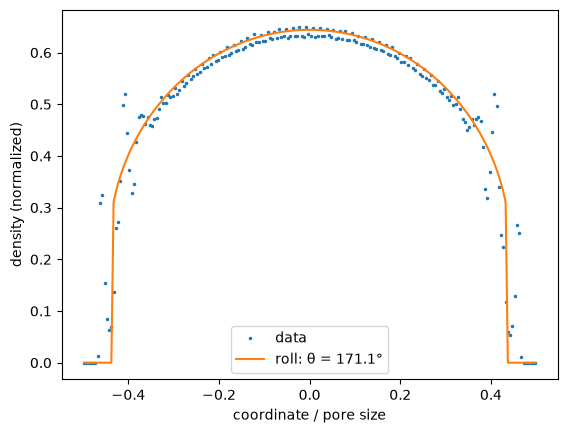

In [6]:
result = comparison.best
print(result)
plot_fit(result);

## 6. θ over time blocks: the error of the angle

Each block is fitted separately; the spread over the blocks is the honest error of θ (if the blocks are longer
than the correlation time — `panda.statistical_inefficiency` checks that). Near θ = 180° the profile depends weakly
on θ, so the spread is large: report θ with it.

slit/roll: 8 block(s)
block t, ps                 theta      delta        phi      shift       loss  flags
   0  2000–2998            177.27   0.032984    0.48699          0    0.02401  
   1  3000–3998            176.11     0.0375    0.48699          0    0.02692  
   2  4000–4998             178.2     0.0375    0.48699          0    0.02789  
   3  5000–5998            166.37     0.0625    0.48699          0     0.0274  
   4  6000–6998               180     0.0625    0.48699          0    0.02452  at bound: theta
   5  7000–7998            167.51     0.0675    0.48699          0    0.02366  
   6  8000–8998            166.18     0.0675    0.48699          0    0.02521  
   7  9000–9998            155.04     0.0775    0.48699          0      0.022  
mean ± standard error: theta = 170.83 ± 3, delta = 0.055685 ± 0.006, phi = 0.48699 ± 0, shift = 0 ± 0


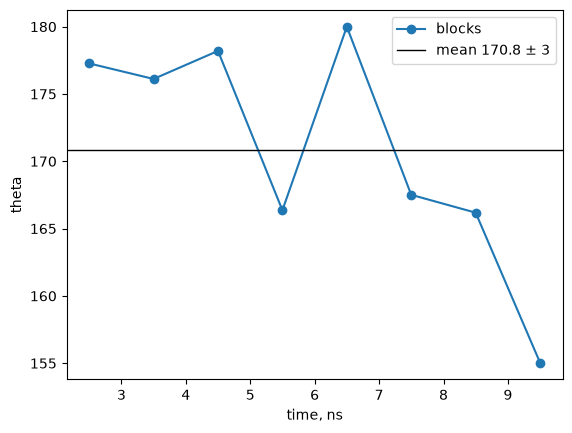

In [7]:
model = pore.interface(result.shape_name)
blocks = panda.fit_blocks(model, profiles, spec)
print(blocks)
plot_blocks(blocks);

## 7. The shape in 2D, axis-centred

A roll wanders along the walls during the run. Axial centering puts its axis at x = 0 in every frame, so the map
shows the bridge itself rather than a smeared average — a direct check of the shape the fit has chosen.

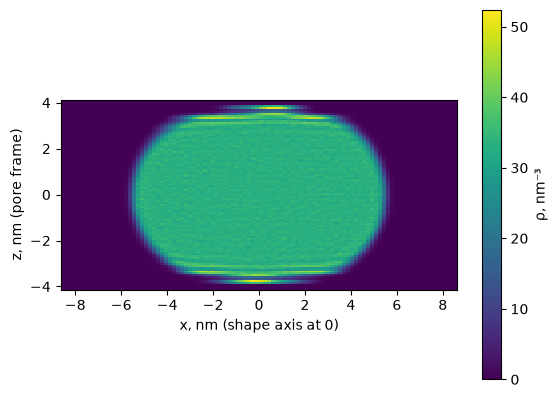

In [8]:
centred = panda.density_map(trajectory, pore, WATER, shape=result.shape_name, start=START, stride=5)
plot_density_map(centred);

## 8. Stability diagram at the measured θ and δ

For every pore length l = L / H and volume fraction φ the shape with the lowest capillary energy S_LV − cos θ·S_SL
wins. The cross marks this pore and this liquid.

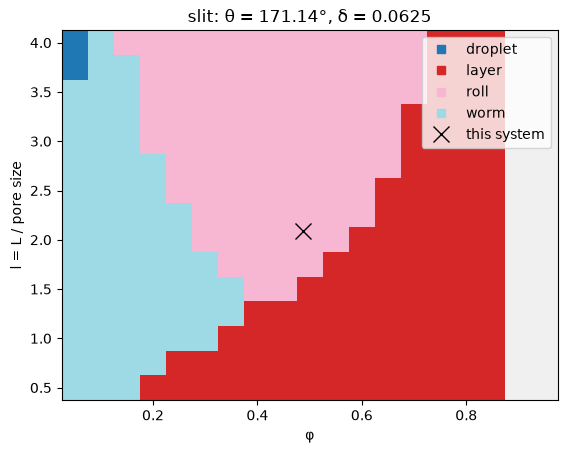

In [9]:
theta, delta, phi = (result.values[name] for name in ("theta", "delta", "phi"))
diagram = panda.stability_diagram(pore, contact_angle_deg=theta, wall_layer=delta,
                                  volume_fractions=np.linspace(0.05, 0.95, 19), length_ratios=np.linspace(0.5, 4.0, 15))
axes = plot_stability(diagram)
axes.plot(phi, pore.length_nm / pore.width_nm, "kx", markersize=12, label="this system")
axes.legend();

## 9. The second liquid: decane

The same three calls. Decane wets graphite (it lies on the walls under the water bridge): formulas for θ < 90° are
not derived for the slit shapes, so the fit stops at the regime boundary and says so with a flag instead of giving a
false angle.

In [10]:
if DECANE is None:
    print("synthetic trajectory: no second liquid")
else:
    decane = panda.density_profile(trajectory, pore, DECANE, start=START, block=BLOCK, per="molecule", stride=5)
    decane_bulk = panda.density_map(trajectory, pore, DECANE, start=START, stride=5, per="molecule").bulk_density()
    decane_fit = pore.interface("roll").fit(decane.mean(), density_bulk_per_nm3=decane_bulk)
    print(f"ρ_bulk of decane ≈ {decane_bulk:.2f} molecules/nm³; φ(water) + φ(decane) = "
          f"{phi + decane_fit.values['phi']:.3f}")
    print(decane_fit)

ρ_bulk of decane ≈ 3.17 molecules/nm³; φ(water) + φ(decane) = 0.959
slit/roll  regime: non_wetting  loss: 0.1989
   theta = 90.5  (free)
   delta = 0.0375  (free)
     phi = 0.471556  (fixed)
   shift = 0  (fixed)
  ! θ at 90° (regime boundary)


## 10. Save the results

Profiles, maps and results are plain files: `.npz` / `.csv` for data, JSON for the pore and the fit (all of them
record the PANDA version). They load back with `panda.ProfileSet.load`, `panda.FitResult.model_validate_json`, ….

In [11]:
from panda_md.plotting import save_fit_figure

profiles.save(OUT / "water_profiles.npz")
(OUT / "pore.json").write_text(pore.model_dump_json(indent=2))
(OUT / "water_fit.json").write_text(result.model_dump_json(indent=2))
save_fit_figure(result, OUT / "water_fit.png")
sorted(path.name for path in OUT.iterdir())

['pore.json', 'water_fit.json', 'water_fit.png', 'water_profiles.npz']

## 11. The same from the shell

The command line builds the same settings and calls the same functions. Without dimensions `panda profile` measures
the slit from the walls and saves it for `panda fit`; `--shape auto` compares all shapes, `--blocks` fits every block.
Here it runs on the profiles saved above (`panda profile TOP TRAJ ...` would compute them from the trajectory).

In [12]:
import shlex
import subprocess
import sys

command = [sys.executable, "-m", "panda_md", "fit", str(OUT / "water_profiles.npz"),
           "--pore-file", str(OUT / "pore.json"), "--shape", "auto", "--rho-bulk", f"{rho_bulk:.3f}", "--blocks",
           "-o", str(OUT / "cli_result.json")]
print("$ panda " + shlex.join(command[3:]))
completed = subprocess.run(command, capture_output=True, text=True)
print(completed.stdout[-1200:], completed.stderr, f"exit code {completed.returncode} (2: a block has a problem flag)")

$ panda fit demo_results/water_profiles.npz --pore-file demo_results/pore.json --shape auto --rho-bulk 33.104 --blocks -o demo_results/cli_result.json


 lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.487, shift = 0; check the fixed values and the bounds
best shape: roll
slit/roll  regime: non_wetting  loss: 0.02617
   theta = 171.14  (free)
   delta = 0.0625  (free)
     phi = 0.486996  (fixed)
   shift = 0  (fixed)
slit/roll: 8 block(s)
block t, ps                 theta      delta        phi      shift       loss  flags
   0  2000–2998            177.28   0.032983      0.487          0    0.02401  
   1  3000–3998            176.11     0.0375      0.487          0    0.02692  
   2  4000–4998             178.2     0.0375      0.487          0    0.02789  
   3  5000–5998            166.37     0.0625      0.487          0     0.0274  
   4  6000–6998               180     0.0625      0.487          0    0.02452  at bound: theta
   5  7000–7998            167.51     0.0675      0.487          0    0.02366  
   6  8000–8998            166.18     0.0675      0.487          0    0.02521  
   7  9000–9998   

## Where next

- `examples/test_panda.ipynb` — a full check of the library (synthetic data and three real systems, PASS / FAIL).
- `examples/05_custom_shape.py` — add your own interface shape from a script.
- `panda shapes` — every pore type, shape, parameter and bound; `panda run panda.toml` — profile + fit from one file.
- Documentation: `make docs` (guide and API reference).